### 01. Perfil e limpeza dos dados

**Projeto:** Campanhas de Marketing Direto e Inativação de Clientes no Varejo Alimentar (PUCRS, Projeto em BI e Analytics, Fase 2)

**Etapa CRISP-DM:** entendimento dos dados e preparação dos dados.

**O que este notebook faz:**
1. Carrega os CSVs do dunnhumby "The Complete Journey" (Kaggle).
2. Mede volume, chaves, ausentes, duplicidades, valores inválidos e intervalo de dias e semanas.
3. Confere os números citados na Fase 1.
4. Aplica as regras de limpeza e salva os arquivos tratados em `data/interim/` (CSV).

**Regra do projeto:** todo número do relatório sai do arquivo `reports/perfil/numeros_perfil.json`, gerado no fim deste notebook.

#### 0. Bibliotecas e pastas

In [ ]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Pasta raiz do projeto 
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_RAW = RAIZ / "data" / "raw"          # CSVs originais do Kaggle
PASTA_INTERIM = RAIZ / "data" / "interim"  # CSVs tratados por este notebook
PASTA_PERFIL = RAIZ / "reports" / "perfil" # tabelas e números do perfil
PASTA_FIG = RAIZ / "reports" / "figuras"
for pasta in [PASTA_INTERIM, PASTA_PERFIL, PASTA_FIG]:
    pasta.mkdir(parents=True, exist_ok=True)

NUM = {}  # dicionário com todos os números que vão para o relatório
print(PASTA_RAW)

c:\Users\Marcel Albuquerque\Documents\1. Atividades\PUCRS - 2023.4 - Business Intelligence e Analytics\Estritório de Projetos\Fase 2\pbia-campanhas-inativacao\data\raw


#### 1. Carga dos CSVs
Cada arquivo vira uma tabela com nome em português. Os nomes das colunas são passados para minúsculas, porque o CSV mistura `household_key` com `BASKET_ID`.

`causal_data.csv` fica fora: não entra nas hipóteses H1 a H3 e é a maior tabela do pacote.

In [2]:
ARQUIVOS = {
    "transacoes": "transaction_data.csv",
    "produtos": "product.csv",
    "demografia": "hh_demographic.csv",
    "campanhas": "campaign_desc.csv",
    "campanha_domicilio": "campaign_table.csv",
    "cupons": "coupon.csv",
    "cupons_resgatados": "coupon_redempt.csv",
}

dados = {}
for nome, arquivo in ARQUIVOS.items():
    df = pd.read_csv(PASTA_RAW / arquivo)
    df.columns = df.columns.str.lower()
    dados[nome] = df
    print(f"{nome:20s} {df.shape[0]:>10,} linhas  {df.shape[1]:>2} colunas")

transacoes            2,595,732 linhas  12 colunas
produtos                 92,353 linhas   7 colunas
demografia                  801 linhas   8 colunas
campanhas                    30 linhas   4 colunas
campanha_domicilio        7,208 linhas   3 colunas
cupons                  124,548 linhas   3 colunas
cupons_resgatados         2,318 linhas   4 colunas


In [3]:
# primeiras linhas da tabela principal
dados["transacoes"].head()

,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


#### 2. Perfil por tabela
Para cada tabela: linhas, colunas, linhas duplicadas, células vazias e se a chave esperada é única.
- `transacoes` e `cupons_resgatados` não têm chave natural (o mesmo item ou cupom pode aparecer mais de uma vez).

In [4]:
CHAVES = {
    "produtos": ["product_id"],
    "demografia": ["household_key"],
    "campanhas": ["campaign"],
    "campanha_domicilio": ["household_key", "campaign"],
    "cupons": ["coupon_upc", "product_id", "campaign"],
}

linhas = []
for nome, df in dados.items():
    chave = CHAVES.get(nome)
    linhas.append({
        "tabela": nome,
        "linhas": len(df),
        "colunas": df.shape[1],
        "linhas_duplicadas": int(df.duplicated().sum()),
        "celulas_ausentes": int(df.isna().sum().sum()),
        "chave": "+".join(chave) if chave else "(sem chave natural)",
        "chaves_repetidas": int(df.duplicated(subset=chave).sum()) if chave else None,
    })
perfil = pd.DataFrame(linhas)
perfil.to_csv(PASTA_PERFIL / "perfil_tabelas.csv", index=False)
NUM["tabelas"] = {r["tabela"]: {k: r[k] for k in ["linhas", "colunas", "linhas_duplicadas", "celulas_ausentes", "chaves_repetidas"]}
                  for r in linhas}
perfil

,tabela,linhas,colunas,linhas_duplicadas,celulas_ausentes,chave,chaves_repetidas
0,transacoes,2595732,12,0,0,(sem chave natural),NaN
1,produtos,92353,7,0,0,product_id,0.0
2,demografia,801,8,0,0,household_key,0.0
3,campanhas,30,4,0,0,campaign,0.0
4,campanha_domicilio,7208,3,0,0,household_key+campaign,0.0
5,cupons,124548,3,5164,0,coupon_upc+product_id+campaign,5164.0
6,cupons_resgatados,2318,4,0,0,(sem chave natural),NaN


#### 3. Perfil por coluna
Tipo, ausentes, valores distintos e mínimo e máximo. Nas colunas de texto, conta também os textos que significam "não informado" ("Unknown", "None"), comuns na demografia.

In [5]:
linhas = []
for nome, df in dados.items():
    for col in df.columns:
        s = df[col]
        item = {"tabela": nome, "coluna": col, "tipo": str(s.dtype),
                "ausentes": int(s.isna().sum()), "distintos": int(s.nunique())}
        if pd.api.types.is_numeric_dtype(s):
            item["minimo"], item["maximo"] = s.min(), s.max()
        else:
            texto = s.astype(str).str.strip().str.upper()
            item["texto_nao_informado"] = int(texto.isin(["", "NONE", "UNKNOWN", "NONE/UNKNOWN"]).sum())
        linhas.append(item)
colunas = pd.DataFrame(linhas)
colunas.to_csv(PASTA_PERFIL / "perfil_colunas.csv", index=False)
colunas

,tabela,coluna,tipo,ausentes,distintos,minimo,maximo,texto_nao_informado
0,transacoes,household_key,int64,0,2500,1.000000e+00,2.500000e+03,NaN
1,transacoes,basket_id,int64,0,276484,2.698485e+10,4.230536e+10,NaN
2,transacoes,day,int64,0,711,1.000000e+00,7.110000e+02,NaN
3,transacoes,product_id,int64,0,92339,2.567100e+04,1.831630e+07,NaN
4,transacoes,quantity,int64,0,11746,0.000000e+00,8.963800e+04,NaN
5,transacoes,sales_value,float64,0,5502,0.000000e+00,8.400000e+02,NaN
6,transacoes,store_id,int64,0,582,1.000000e+00,3.428000e+04,NaN
7,transacoes,retail_disc,float64,0,2414,-1.800000e+02,3.990000e+00,NaN
8,transacoes,trans_time,int64,0,1440,0.000000e+00,2.359000e+03,NaN
9,transacoes,week_no,int64,0,102,1.000000e+00,1.020000e+02,NaN


#### 4. Valores inválidos nas transações
Cada regra conta linhas suspeitas. Contar não é excluir: a decisão fica na seção 8.

Sobre a semana: na base, a semana 1 tem os dias 1 a 5 e as demais têm 7 dias. A regra confere se todas as linhas seguem esse padrão.

In [6]:
t = dados["transacoes"]
semana_esperada = (t["day"] + 1) // 7 + 1

regras = {
    "quantity <= 0": t["quantity"] <= 0,
    "sales_value < 0": t["sales_value"] < 0,
    "sales_value == 0": t["sales_value"] == 0,
    "retail_disc > 0 (inclui ruído de ponto flutuante)": t["retail_disc"] > 0,
    "retail_disc > 0,01 (desconto positivo real)": t["retail_disc"] > 0.01,
    "coupon_disc > 0": t["coupon_disc"] > 0,
    "coupon_match_disc > 0": t["coupon_match_disc"] > 0,
    "trans_time fora do formato HHMM": (t["trans_time"] // 100 > 23) | (t["trans_time"] % 100 > 59),
    "week_no fora do padrão (day+1)//7+1": t["week_no"] != semana_esperada,
    "day <= 0": t["day"] <= 0,
}
tab_regras = pd.DataFrame([{"regra": r, "linhas": int(m.sum()), "pct": round(100 * m.mean(), 4)} for r, m in regras.items()])
tab_regras.to_csv(PASTA_PERFIL / "regras_transacoes.csv", index=False)
NUM["regras_transacoes"] = dict(zip(tab_regras["regra"], tab_regras["linhas"]))
tab_regras

,regra,linhas,pct
0,quantity <= 0,14466,0.5573
1,sales_value < 0,0,0.0000
2,sales_value == 0,18850,0.7262
3,retail_disc > 0 (inclui ruído de ponto flutuante),36,0.0014
4,"retail_disc > 0,01 (desconto positivo real)",6,0.0002
5,coupon_disc > 0,0,0.0000
6,coupon_match_disc > 0,0,0.0000
7,trans_time fora do formato HHMM,0,0.0000
8,week_no fora do padrão (day+1)//7+1,0,0.0000
9,day <= 0,0,0.0000


#### 5. Integridade referencial
Verificando se cada código usado numa tabela existe na tabela de referência. Um valor sem par é chamado de **órfão**.

In [7]:
hh_base = set(t["household_key"])
checagens = [
    ("transacoes.product_id em produtos", t["product_id"], set(dados["produtos"]["product_id"])),
    ("demografia.household_key em transacoes", dados["demografia"]["household_key"], hh_base),
    ("campanha_domicilio.household_key em transacoes", dados["campanha_domicilio"]["household_key"], hh_base),
    ("campanha_domicilio.campaign em campanhas", dados["campanha_domicilio"]["campaign"], set(dados["campanhas"]["campaign"])),
    ("cupons.campaign em campanhas", dados["cupons"]["campaign"], set(dados["campanhas"]["campaign"])),
    ("cupons.product_id em produtos", dados["cupons"]["product_id"], set(dados["produtos"]["product_id"])),
    ("cupons_resgatados.household_key em transacoes", dados["cupons_resgatados"]["household_key"], hh_base),
    ("cupons_resgatados.coupon_upc em cupons", dados["cupons_resgatados"]["coupon_upc"], set(dados["cupons"]["coupon_upc"])),
]
ref = pd.DataFrame([{"checagem": nome, "linhas": len(serie), "linhas_orfas": int((~serie.isin(base)).sum())}
                    for nome, serie, base in checagens])
ref.to_csv(PASTA_PERFIL / "integridade_referencial.csv", index=False)
NUM["integridade"] = dict(zip(ref["checagem"], ref["linhas_orfas"]))
ref

,checagem,linhas,linhas_orfas
0,transacoes.product_id em produtos,2595732,0
1,demografia.household_key em transacoes,801,0
2,campanha_domicilio.household_key em transacoes,7208,0
3,campanha_domicilio.campaign em campanhas,7208,0
4,cupons.campaign em campanhas,124548,0
5,cupons.product_id em produtos,124548,0
6,cupons_resgatados.household_key em transacoes,2318,0
7,cupons_resgatados.coupon_upc em cupons,2318,0


#### 6. Intervalo temporal
A base não tem datas de calendário: `day` e `week_no` são números sequenciais.

In [8]:
c = dados["campanhas"]
tempo = {
    "dia_min": int(t["day"].min()), "dia_max": int(t["day"].max()),
    "semana_min": int(t["week_no"].min()), "semana_max": int(t["week_no"].max()),
    "dias_distintos": int(t["day"].nunique()), "semanas_distintas": int(t["week_no"].nunique()),
    "campanha_dia_inicio_min": int(c["start_day"].min()), "campanha_dia_fim_max": int(c["end_day"].max()),
    "campanhas_com_inicio_apos_fim": int((c["start_day"] > c["end_day"]).sum()),
}
NUM["tempo"] = tempo
tempo

{'dia_min': 1,
 'dia_max': 711,
 'semana_min': 1,
 'semana_max': 102,
 'dias_distintos': 711,
 'semanas_distintas': 102,
 'campanha_dia_inicio_min': 224,
 'campanha_dia_fim_max': 719,
 'campanhas_com_inicio_apos_fim': 0}

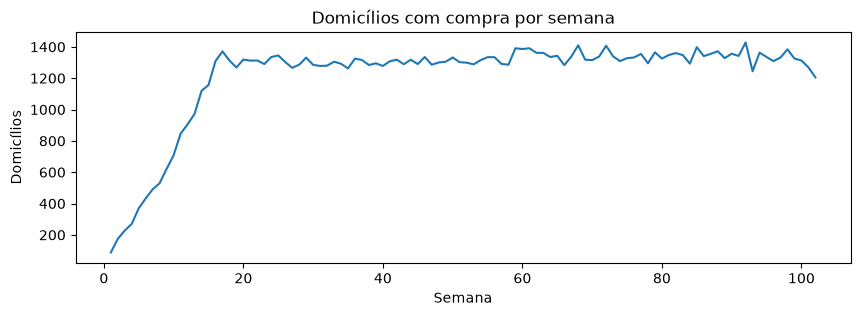

In [9]:
# Domicílios com compra por semana: mostra que os clientes entraram aos poucos na base
semanal = t.groupby("week_no").agg(domicilios=("household_key", "nunique"),
                                   cestas=("basket_id", "nunique"),
                                   receita=("sales_value", "sum"))
semanal.to_csv(PASTA_PERFIL / "serie_semanal.csv")
ax = semanal["domicilios"].plot(figsize=(10, 3), title="Domicílios com compra por semana")
ax.set_xlabel("Semana"); ax.set_ylabel("Domicílios")
plt.savefig(PASTA_FIG / "01_domicilios_semana.png", dpi=120, bbox_inches="tight")
plt.show()

In [10]:
# Primeira e última semana de compra de cada domicílio
vida = t.groupby("household_key")["week_no"].agg(primeira="min", ultima="max")
NUM["primeira_semana_quantis"] = {str(q): int(v) for q, v in vida["primeira"].quantile([.5, .9, .99, 1]).items()}
NUM["ultima_semana_quantis"] = {str(q): int(v) for q, v in vida["ultima"].quantile([0, .01, .1, .5]).items()}
vida.describe()

,primeira,ultima
count,2500.00000,2500.000000
mean,10.11520,98.580800
std,5.60165,8.957386
min,1.00000,8.000000
25%,6.00000,99.000000
50%,11.00000,101.000000
75%,14.00000,102.000000
max,97.00000,102.000000


#### 7. Validação dos números citados na Fase 1
| Afirmação da Fase 1 | Como é verificada |
|---|---|
| 2.500 domicílios | `household_key` distintos nas transações |
| cerca de 2,6 milhões de transações | linhas de `transaction_data` (cada linha é um item da cesta) |
| parcela com demografia | domicílios em `hh_demographic` sobre o total |
| 2 anos | semanas cobertas pela base |

In [11]:
n_hh = t["household_key"].nunique()
n_demo = dados["demografia"]["household_key"].nunique()
n_camp = dados["campanha_domicilio"]["household_key"].nunique()
n_resg = dados["cupons_resgatados"]["household_key"].nunique()
fase1 = {
    "domicilios_transacoes": int(n_hh),
    "linhas_transacoes": len(t),
    "cestas_distintas": int(t["basket_id"].nunique()),
    "domicilios_com_demografia": int(n_demo),
    "pct_com_demografia": round(100 * n_demo / n_hh, 1),
    "domicilios_com_campanha": int(n_camp),
    "domicilios_com_resgate": int(n_resg),
    "campanhas": int(dados["campanhas"]["campaign"].nunique()),
    "produtos": int(dados["produtos"]["product_id"].nunique()),
    "lojas": int(t["store_id"].nunique()),
    "receita_total_sales_value": round(float(t["sales_value"].sum()), 2),
    "pct_com_campanha": round(100 * n_camp / n_hh, 1),
    "pct_com_resgate": round(100 * n_resg / n_hh, 1),
}
NUM["fase1"] = fase1

conferencia = pd.DataFrame([
    ("2.500 domicílios", 2500, fase1["domicilios_transacoes"]),
    ("cerca de 2,6 milhões de linhas", 2_600_000, fase1["linhas_transacoes"]),
    ("2 anos (104 semanas)", 104, tempo["semana_max"] - tempo["semana_min"] + 1),
], columns=["afirmacao", "citado", "observado"])
conferencia["diferenca_pct"] = (100 * (conferencia["observado"] / conferencia["citado"] - 1)).round(1)
conferencia

,afirmacao,citado,observado,diferenca_pct
0,2.500 domicílios,2500,2500,0.0
1,"cerca de 2,6 milhões de linhas",2600000,2595732,-0.2
2,2 anos (104 semanas),104,102,-1.9


#### 8. Limpeza
Princípio: **marcar, não apagar**. A linha suspeita recebe uma coluna de marcação (flag) e cada notebook seguinte decide se usa ou não.

1. `quantity <= 0` ou `sales_value <= 0`: marcadas em `flag_valor_invalido` e fora dos cálculos de valor e de compra.
2. Duplicidade completa nas transações: marcada em `flag_duplicada`.
3. Demografia: "Unknown" e "None" viram vazio.
4. Receita do projeto = `sales_value` (valor recebido pelo varejista).
5. `coupon.csv`: linhas idênticas removidas, pois é tabela de referência e a cópia não traz informação.

In [12]:
t["flag_valor_invalido"] = (t["quantity"] <= 0) | (t["sales_value"] <= 0)
t["flag_duplicada"] = t.duplicated(keep="first")
dados["transacoes"] = t

d = dados["demografia"]
for col in d.select_dtypes("object").columns:
    texto = d[col].astype(str).str.strip().str.upper()
    d[col] = d[col].mask(texto.isin(["UNKNOWN", "NONE", ""]))
dados["demografia"] = d

linhas_antes = len(dados["cupons"])
dados["cupons"] = dados["cupons"].drop_duplicates().reset_index(drop=True)

NUM["limpeza"] = {
    "linhas_flag_valor_invalido": int(t["flag_valor_invalido"].sum()),
    "linhas_flag_duplicada": int(t["flag_duplicada"].sum()),
    "receita_em_linhas_invalidas": round(float(t.loc[t["flag_valor_invalido"], "sales_value"].sum()), 2),
    "cupons_linhas_duplicadas_removidas": linhas_antes - len(dados["cupons"]),
    "campanhas_terminam_apos_fim_da_base": int((dados["campanhas"]["end_day"] > tempo["dia_max"]).sum()),
}
NUM["limpeza"]

C:\Windows\Temp\ipykernel_37772\3983509354.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in d.select_dtypes("object").columns:


{'linhas_flag_valor_invalido': 18917,
 'linhas_flag_duplicada': 0,
 'receita_em_linhas_invalidas': 19.28,
 'cupons_linhas_duplicadas_removidas': 5164,
 'campanhas_terminam_apos_fim_da_base': 1}

#### 9. Viabilidade das janelas de inativação
Antes de definir os cortes do notebook 02, mede-se quantos domicílios ficariam inativos em cada janela proposta.
Observação de 26 semanas: treino nas semanas 53 a 78 e teste nas semanas 69 a 94 (as duas começam depois da entrada gradual e do início das campanhas).

In [13]:
semana_domicilio = t[["household_key", "week_no"]].drop_duplicates()

def taxa_inativos(obs_ini, obs_fim, perf):
    ativos = set(semana_domicilio.loc[semana_domicilio["week_no"].between(obs_ini, obs_fim), "household_key"])
    voltaram = set(semana_domicilio.loc[semana_domicilio["week_no"].between(obs_fim + 1, obs_fim + perf), "household_key"])
    inativos = len(ativos - voltaram)
    return {"obs": f"{obs_ini}-{obs_fim}", "perf_semanas": perf, "ativos": len(ativos),
            "inativos": inativos, "pct": round(100 * inativos / len(ativos), 1)}

viab = [taxa_inativos(a, b, p) for a, b in [(53, 78), (69, 94)] for p in (4, 8, 12) if b + p <= tempo["semana_max"]]
NUM["viabilidade_janelas"] = viab
pd.DataFrame(viab)

,obs,perf_semanas,ativos,inativos,pct
0,53-78,4,2409,419,17.4
1,53-78,8,2409,211,8.8
2,53-78,12,2409,141,5.9
3,69-94,4,2417,429,17.7
4,69-94,8,2417,244,10.1


#### 10. Gravação dos arquivos tratados e dos números

In [14]:
for nome, df in dados.items():
    df.to_csv(PASTA_INTERIM / f"{nome}.csv", index=False)

with open(PASTA_PERFIL / "numeros_perfil.json", "w", encoding="utf-8") as f:
    json.dump(NUM, f, ensure_ascii=False, indent=2)
sorted(p.name for p in PASTA_INTERIM.glob("*.csv"))

['campanha_domicilio.csv',
 'campanhas.csv',
 'cupons.csv',
 'cupons_resgatados.csv',
 'demografia.csv',
 'produtos.csv',
 'transacoes.csv']

#### 11. Achados

In [15]:
f, tp, lp = NUM["fase1"], NUM["tempo"], NUM["limpeza"]
q1 = NUM["primeira_semana_quantis"]
print(f"Base: {f['linhas_transacoes']:,} itens de venda, {f['cestas_distintas']:,} cestas, {f['domicilios_transacoes']:,} domicílios, "
      f"{f['produtos']:,} produtos, {f['lojas']} lojas, dias {tp['dia_min']} a {tp['dia_max']} (semanas {tp['semana_min']} a {tp['semana_max']}).")
print(f"Cobertura: demografia {f['pct_com_demografia']}%, campanha {f['pct_com_campanha']}%, resgate de cupom {f['pct_com_resgate']}% dos domicílios.")
print(f"Entrada gradual: metade dos domicílios faz a 1a compra até a semana {q1['0.5']}; 99% até a semana {q1['0.99']}.")
print(f"Campanhas: do dia {tp['campanha_dia_inicio_min']} ao dia {tp['campanha_dia_fim_max']}; {lp['campanhas_terminam_apos_fim_da_base']} termina depois do fim da base.")
print(f"Linhas marcadas como valor inválido: {lp['linhas_flag_valor_invalido']:,} (receita nelas: {lp['receita_em_linhas_invalidas']}).")
print(f"Duplicatas removidas em cupons: {lp['cupons_linhas_duplicadas_removidas']:,}. Órfãos na integridade referencial: {sum(NUM['integridade'].values())}.")

Base: 2,595,732 itens de venda, 276,484 cestas, 2,500 domicílios, 92,353 produtos, 582 lojas, dias 1 a 711 (semanas 1 a 102).
Cobertura: demografia 32.0%, campanha 63.4%, resgate de cupom 17.4% dos domicílios.
Entrada gradual: metade dos domicílios faz a 1a compra até a semana 11; 99% até a semana 18.
Campanhas: do dia 224 ao dia 719; 1 termina depois do fim da base.
Linhas marcadas como valor inválido: 18,917 (receita nelas: 19.28).
Duplicatas removidas em cupons: 5,164. Órfãos na integridade referencial: 0.
